###implement k mean and k medoid

Aim
to implement k means and k medoid clustering algo using python and plot the scatter plot for the output.

theory
k means clustering

k means is a centroid based clustering algo
for a given value of k the algo
1. select the k initial centroids.
2. assigns each data point to its nearest centroid
3. calculates the new centroid of each cluster
4. reassigns the point based on the new centroids
 5. repeats the process until the centroid becomes stable
 the centroid is calculated using the mean of all points in the cluster


 k medoid clustering
k medoid is similar to k means but instead of using the measn as the cluster center it selects an actual dat point as the cluster center. this point is called medoid.
the algo attempts to select medoids such as the total distance between the data points and their assigned medoids is minimized.
k medoids is generally more robust to outliers than k means.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances

# 1. Create a small synthetic 2D dataset (3 clusters)
np.random.seed(42)
X1 = np.random.randn(15, 2) + np.array([2, 2])
X2 = np.random.randn(15, 2) + np.array([-2, -2])
X3 = np.random.randn(15, 2) + np.array([2, -2])
X = np.vstack([X1, X2, X3])

k = 3


In [ ]:
# 2. Implement K-Means using scikit-learn
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X)
kmeans_centers = kmeans.cluster_centers_

print("K-Means Centroids:")
for i, center in enumerate(kmeans_centers):
    print(f"Centroid {i+1}: {center}")

K-Means Centroids:
Centroid 1: [ 2.06117074 -1.90514319]
Centroid 2: [1.82599475 1.79771146]
Centroid 3: [-2.0208902  -2.06865459]


In [ ]:
# 3. Implement a simple version of K-Medoids
# Initialize medoids randomly from the dataset points
medoid_indices = np.random.choice(len(X), k, replace=False)
medoids = X[medoid_indices]

for _ in range(10): # Iterative refinement
    # Assign each point to the closest medoid
    distances = pairwise_distances(X, medoids, metric='euclidean')
    kmedoids_labels = np.argmin(distances, axis=1)

    # Update medoids: choose the point in each cluster that minimizes sum of distances
    new_medoids = []
    for i in range(k):
        cluster_points = X[kmedoids_labels == i]
        if len(cluster_points) > 0:
            # Find point with minimum total distance to all other points in the cluster
            intra_distances = pairwise_distances(cluster_points, cluster_points, metric='euclidean')
            best_idx = np.argmin(intra_distances.sum(axis=1))
            new_medoids.append(cluster_points[best_idx])
        else:
            # Fallback if cluster becomes empty
            new_medoids.append(medoids[i])
    medoids = np.array(new_medoids)

print("K-Medoids (Final Cluster Centers / Medoids):")
for i, medoid in enumerate(medoids):
    print(f"Medoid {i+1}: {medoid}")

K-Medoids (Final Cluster Centers / Medoids):
Medoid 1: [1.76584663 1.76586304]
Medoid 2: [ 1.78032811 -1.64288743]
Medoid 3: [-2.11564828 -2.3011037 ]


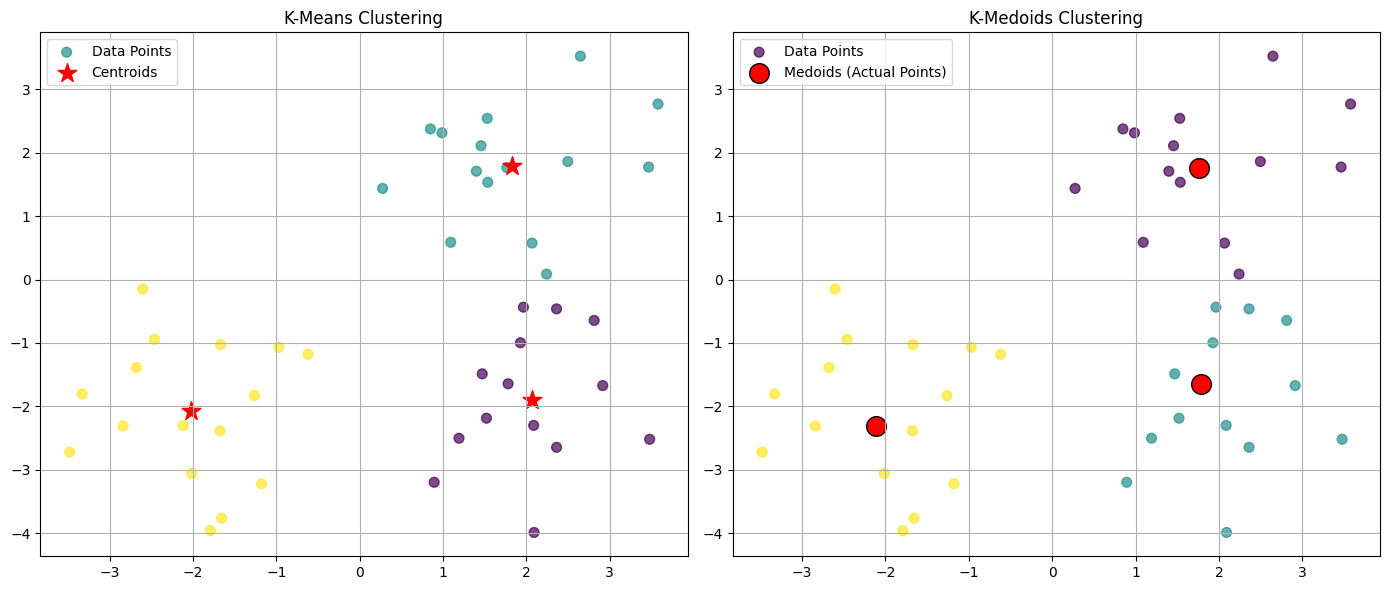

In [ ]:
# 4. Plot both results side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Plot K-Means
ax1.scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap='viridis', s=50, alpha=0.7, label='Data Points')
ax1.scatter(kmeans_centers[:, 0], kmeans_centers[:, 1], c='red', marker='*', s=200, label='Centroids')
ax1.set_title('K-Means Clustering')
ax1.legend()
ax1.grid(True)

# Plot K-Medoids
ax2.scatter(X[:, 0], X[:, 1], c=kmedoids_labels, cmap='viridis', s=50, alpha=0.7, label='Data Points')
ax2.scatter(medoids[:, 0], medoids[:, 1], c='red', marker='o', edgecolors='black', s=200, label='Medoids (Actual Points)')
ax2.set_title('K-Medoids Clustering')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()
